<a href="https://colab.research.google.com/github/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification/blob/main/notebooks/04_disease_type_multilabel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Disease type: DR, MH and ODC (multi-label)

Predicts **Diabetic Retinopathy (DR)**, **Media Haze (MH)** and **Optic Disc Cupping (ODC)** as three independent yes/no outputs.

**What changed from the original Part 4 and Part 5 notebooks**

| Original | Problem | Now |
|---|---|---|
| Softmax over 3 classes | An eye with both DR and ODC could only get one label; 99 training images have 2+ of these | Three sigmoid outputs, each disease predicted independently |
| Only the 724 images sorted into DR/MH/ODC folders | About 150 target-disease images were lost to other folders; the model never saw healthy eyes or other diseases, so it could not learn to say "none of these" | All 1,920 training images; images without a target disease are negatives for all three |
| `X_train` computed once with InceptionV3 | The Xception, VGG16, MobileNetV2, EfficientNetB5 and SE-ResNeXt results were all InceptionV3 features with different heads | Each backbone is trained end to end on its own |
| Same shuffle/label misalignment as Part 3 | Accuracy 30-46%, below always predicting DR (47%) | Fixed via `tf.data` |
| Test set used for early stopping | Optimistic score | Validation set for early stopping and thresholds |
| Accuracy only | Hides per-disease performance | Per-disease AUC, PR-AUC, F1, sensitivity, specificity, with thresholds tuned on validation |

Runtime on a Colab T4: roughly 15-25 minutes per backbone.

In [2]:
# --- Setup (run once per session) -------------------------------------------
# On Colab: mounts Google Drive, clones this repo and installs requirements.
# Locally: just makes the `iluminado` package importable.
import os, sys, subprocess

REPO_URL = "https://github.com/cathykam2006/Capstone-Project-Illuminado-Retinal--Image-Classification.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/repo"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/repo"], check=True)
    else:   # always use the latest code from GitHub
        subprocess.run(["git", "-C", "/content/repo", "pull", "-q"], check=True)
    os.chdir("/content/repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

REPO_DIR = next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.isdir(os.path.join(p, "iluminado")))
sys.path.insert(0, REPO_DIR)
print("Repo:", REPO_DIR)

Mounted at /content/drive
Repo: /content/repo


In [3]:
# --- Config: edit these paths ---------------------------------------------------
# PROJECT_DIR holds the cached images, trained models and results. On Colab it
# lives on your Google Drive so it survives between sessions.
PROJECT_DIR = "/content/drive/MyDrive/iluminado" if IN_COLAB else os.path.join(REPO_DIR, "work")
LABEL_DIR = os.path.join(REPO_DIR, "data")            # the three RFMiD label CSVs (in the repo)
MANIFEST = os.path.join(PROJECT_DIR, "manifest.csv")  # written by notebook 01
os.makedirs(PROJECT_DIR, exist_ok=True)

In [4]:
# --- Training config ---------------------------------------------------------------
IMG_SIZE = 384        # fundus lesions are small; 384 keeps far more detail than the old 150-256
BATCH_SIZE = 16
BACKBONES = ["efficientnet_b0", "densenet121", "convnext_tiny"]   # different families -> more useful ensemble
HEAD_EPOCHS, FINETUNE_EPOCHS = 5, 30
SEED = 42

import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus or "none (training will be very slow; in Colab use Runtime > Change runtime type > GPU)")
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")   # ~2x faster on T4/A100

from iluminado.data import make_dataset, TARGET_DISEASES, localize, build_manifest, cache_images
from iluminado import models as M, evaluate as E
m = pd.read_csv(MANIFEST)
missing = sum(not os.path.exists(p) for p in m.path)
print(f"{missing} of {len(m)} cached images missing on Drive")
if missing == 0 and IN_COLAB:
    m = localize(m)          # train from local disk, not Google Drive: many times faster
elif missing:
    # The Drive copy is incomplete (Drive sometimes drops files when a session ends mid-upload).
    # Rebuild the image cache on this machine's local disk instead: about 15-20 minutes.
    from iluminado.download import fetch_hf
    root, labels = fetch_hf("/content/rfmid" if IN_COLAB else os.path.join(PROJECT_DIR, "rfmid"),
                            official_dir=os.path.join(REPO_DIR, "data"))
    m = cache_images(build_manifest(root, labels), "/content/local_cache_512" if IN_COLAB else os.path.join(PROJECT_DIR, "cache_512"), size=512)
MODEL_DIR = os.path.join(PROJECT_DIR, "models"); os.makedirs(MODEL_DIR, exist_ok=True)
RESULTS_DIR = os.path.join(PROJECT_DIR, "results"); os.makedirs(RESULTS_DIR, exist_ok=True)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
0 of 3200 cached images missing on Drive
  copied 500/3200 images to local disk
  copied 1000/3200 images to local disk
  copied 1500/3200 images to local disk
  copied 2000/3200 images to local disk
  copied 2500/3200 images to local disk
  copied 3000/3200 images to local disk
  copied 3200/3200 images to local disk


## Data

In [5]:
TASK = "multilabel"
LABELS = TARGET_DISEASES
split = {s: m[m.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
y = {s: split[s][LABELS].to_numpy("float32") for s in split}

train_ds = make_dataset(split["train"].path, y["train"], IMG_SIZE, BATCH_SIZE, training=True, seed=SEED)
val_ds = make_dataset(split["val"].path, y["val"], IMG_SIZE, BATCH_SIZE, training=False)
test_ds = make_dataset(split["test"].path, y["test"], IMG_SIZE, BATCH_SIZE, training=False)

pos_weight = M.positive_weights(y["train"])
pd.DataFrame({s: y[s].sum(axis=0).astype(int) for s in y}, index=LABELS).assign(pos_weight=pos_weight.round(2))

,train,val,test,pos_weight
DR,376,132,124,4.11
MH,317,102,104,5.06
ODC,282,72,91,5.81


## Train each backbone

In [6]:
probs = {"val": {}, "test": {}}
for bb in BACKBONES:
    path = os.path.join(MODEL_DIR, f"{TASK}_{bb}.keras")
    if os.path.exists(path):
        print(f"[{bb}] found saved model, skipping training")
        model = M.load(path)
    else:
        print(f"\n===== {bb} =====")
        keras.backend.clear_session()
        model = M.build_model(bb, IMG_SIZE, n_outputs=len(LABELS))
        h1, h2 = M.train(model, train_ds, val_ds, pos_weight, n_outputs=len(LABELS), ckpt_path=path,
                         head_epochs=HEAD_EPOCHS, finetune_epochs=FINETUNE_EPOCHS)
        model = M.load(path)
        pd.DataFrame(h2.history).to_csv(os.path.join(RESULTS_DIR, f"{TASK}_{bb}_history.csv"), index=False)
    for s, ds in (("val", val_ds), ("test", test_ds)):
        probs[s][bb] = E.predict(model, ds)
    np.save(os.path.join(RESULTS_DIR, f"{TASK}_{bb}_val.npy"), probs["val"][bb])
    np.save(os.path.join(RESULTS_DIR, f"{TASK}_{bb}_test.npy"), probs["test"][bb])


===== efficientnet_b0 =====
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
120/120 - 50s - 415ms/step - auc: 0.7540 - loss: 0.9550 - pr_auc: 0.4457 - val_auc: 0.8565 - val_loss: 0.7636 - val_pr_auc: 0.6290
Epoch 2/5
120/120 - 5s - 40ms/step - auc: 0.8528 - loss: 0.7861 - pr_auc: 0.6118 - val_auc: 0.8690 - val_loss: 0.7008 - val_pr_auc: 0.6502
Epoch 3/5
120/120 - 5s - 40ms/step - auc: 0.8673 - loss: 0.7364 - pr_auc: 0.6475 - val_auc: 0.8786 - val_loss: 0.6832 - val_pr_auc: 0.6610
Epoch 4/5
120/120 - 5s - 41ms/step - auc: 0.8822 - loss: 0.6996 - pr_auc: 0.6686 - val_auc: 0.8852 - val_loss: 0.6401 - val_pr_auc: 0.6724
Epoch 5/5
120/120 - 5s - 40ms/step - auc: 0.8927 - loss: 0.6735 - pr_auc: 0.6849 - val_auc: 0.8880 - val_loss: 0.6256 - val_pr_auc: 0.6761
Epoch 1/30
120/120 - 46s - 387ms/step - auc: 0.8933 - loss: 0.6552 - pr_auc: 0.6943 - val_auc: 0.9018 - val_loss: 0.5816 - val_pr_auc: 0.6914 - learning_rate: 3.0000e-05
Epoch 2/30
120/120 - 6s - 53ms/step - auc: 0.9196 - l

## Classical baseline (no deep learning)

The same 34 image statistics and three classical models as in notebook 03, one set per disease.

In [7]:
from sklearn.metrics import roc_auc_score
from iluminado.baseline import features_for, fit_predict
feats = {s: features_for(split[s].path.tolist()) for s in split}
probs["val"]["classical baseline"], probs["test"]["classical baseline"] = fit_predict(feats["train"], y["train"], [feats["val"], feats["test"]])
print("classical baseline validation macro AUC:", round(roc_auc_score(y["val"], probs["val"]["classical baseline"], average="macro"), 3))

classical baseline validation macro AUC: 0.852


## Ensemble and per-disease thresholds (validation set only)

Each disease gets its own threshold, chosen to maximise F1 on validation.

In [8]:
from sklearn.metrics import roc_auc_score
yv, yt = y["val"], y["test"]
val_auc = {bb: roc_auc_score(yv, p, average="macro") for bb, p in probs["val"].items()}
probs["val"]["ensemble"] = E.ensemble({k: probs["val"][k] for k in BACKBONES}, val_auc)
probs["test"]["ensemble"] = E.ensemble({k: probs["test"][k] for k in BACKBONES}, val_auc)
thresholds = {k: [E.threshold_for_f1(yv[:, j], p[:, j]) for j in range(len(LABELS))] for k, p in probs["val"].items()}
pd.Series(val_auc, name="validation macro AUC").round(3)

,validation macro AUC
efficientnet_b0,0.941
densenet121,0.941
convnext_tiny,0.947
classical baseline,0.852


## Final test results (test set used once)

In [9]:
summary = {}
for k, p in probs["test"].items():
    rep = E.multilabel_report(yt, p, thresholds[k], LABELS)
    summary[k] = rep.loc["macro avg", ["AUC", "PR-AUC", "F1", "sensitivity", "specificity"]]
summary = pd.DataFrame(summary).T
lo, hi = E.bootstrap_ci(yt, probs["test"]["ensemble"], metric=lambda a, b: roc_auc_score(a, b, average="macro"))
print(f"Ensemble macro AUC 95% CI: {lo:.3f}-{hi:.3f}")
summary.to_csv(os.path.join(RESULTS_DIR, f"{TASK}_test_summary.csv"))
summary.round(3)

Ensemble macro AUC 95% CI: 0.938-0.962


,AUC,PR-AUC,F1,sensitivity,specificity
efficientnet_b0,0.942,0.800,0.703,0.775,0.919
densenet121,0.940,0.807,0.722,0.752,0.936
convnext_tiny,0.950,0.824,0.712,0.771,0.927
classical baseline,0.837,0.594,0.563,0.689,0.839
ensemble,0.950,0.830,0.711,0.712,0.952


In [10]:
per_disease = E.multilabel_report(yt, probs["test"]["ensemble"], thresholds["ensemble"], LABELS)
per_disease.to_csv(os.path.join(RESULTS_DIR, f"{TASK}_ensemble_per_disease.csv"))
per_disease.round(3)

,n_positive,AUC,PR-AUC,prevalence (PR-AUC of random guess),threshold,F1,sensitivity,specificity
disease,,,,,,,,
DR,124.000,0.979,0.922,0.194,0.644,0.815,0.815,0.955
MH,104.000,0.975,0.911,0.162,0.569,0.785,0.913,0.920
ODC,91.000,0.898,0.658,0.142,0.772,0.532,0.407,0.980
macro avg,106.333,0.950,0.830,0.166,NaN,0.711,0.712,0.952


### Does the ensemble beat its best single model?

Macro AUC difference on the same resampled test images; if the 95% interval excludes 0 the gain is real.

In [11]:
best_single = max(BACKBONES, key=lambda k: val_auc[k])
macro = lambda a, b: roc_auc_score(a, b, average="macro")
rows = []
for other in [best_single, "classical baseline"]:
    d, lo, hi, verdict = E.paired_bootstrap_diff(yt, probs["test"]["ensemble"], probs["test"][other], metric=macro)
    rows.append({"ensemble minus": other, "macro AUC difference": round(d, 3), "95% CI": f"{lo:+.3f} to {hi:+.3f}",
                 "verdict": verdict.replace("A ", "ensemble ")})
pd.DataFrame(rows)

,ensemble minus,macro AUC difference,95% CI,verdict
0,convnext_tiny,0.001,-0.004 to +0.005,no clear difference
1,classical baseline,0.114,+0.093 to +0.137,ensemble clearly better


PR-AUC should be read against the prevalence column: for a rare disease, a random model's PR-AUC equals its prevalence, so 0.6 on a 6%-prevalence disease is a large improvement over chance.

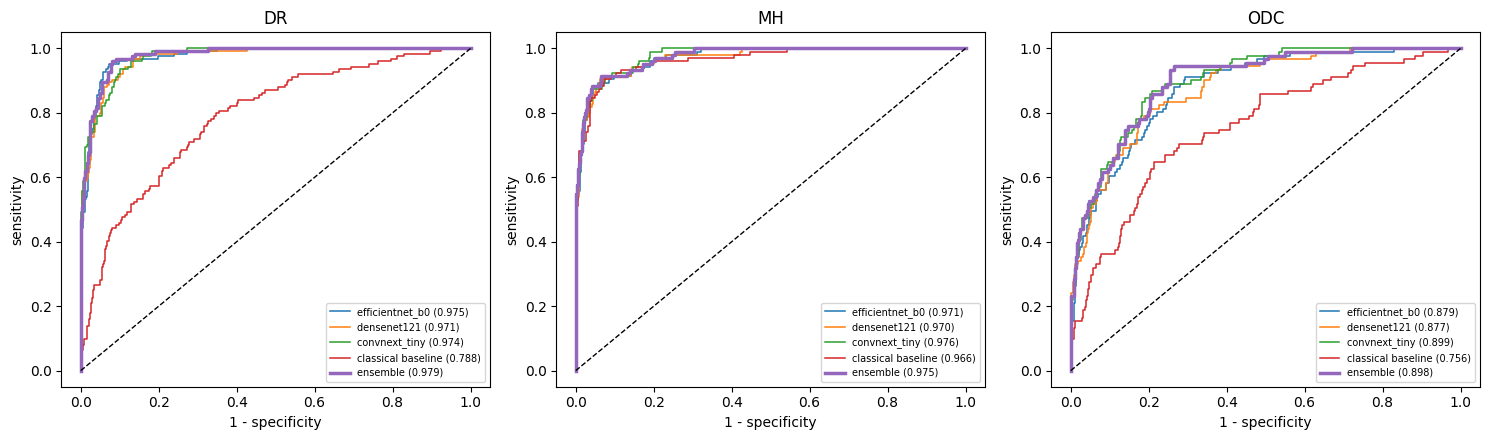

In [12]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, len(LABELS), figsize=(5 * len(LABELS), 4.5))
for j, d in enumerate(LABELS):
    for k, p in probs["test"].items():
        fpr, tpr, _ = roc_curve(yt[:, j], p[:, j])
        axes[j].plot(fpr, tpr, lw=2.5 if k == "ensemble" else 1.1, label=f"{k} ({roc_auc_score(yt[:, j], p[:, j]):.3f})")
    axes[j].plot([0, 1], [0, 1], "k--", lw=1); axes[j].set_title(d); axes[j].legend(fontsize=7)
    axes[j].set(xlabel="1 - specificity", ylabel="sensitivity")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f"{TASK}_roc.png"), dpi=150); plt.show()

## Grad-CAM per disease

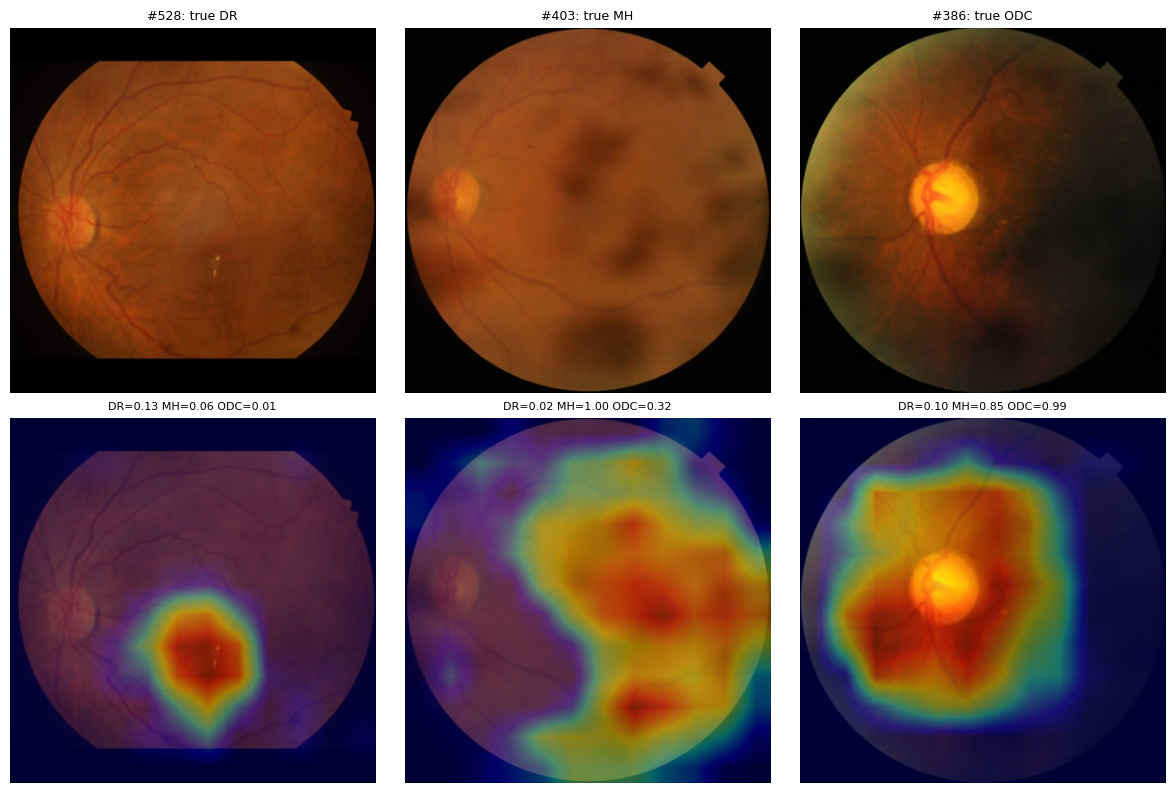

In [13]:
from PIL import Image
from iluminado.gradcam import gradcam, overlay
best = max(BACKBONES, key=lambda k: val_auc[k])
model = M.load(os.path.join(MODEL_DIR, f"{TASK}_{best}.keras"))
fig, axes = plt.subplots(2, len(LABELS), figsize=(4 * len(LABELS), 8))
for j, d in enumerate(LABELS):
    row = split["test"][split["test"][d] == 1].sample(1, random_state=2).iloc[0]
    img = np.asarray(Image.open(row.path).convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype="float32")
    p = model.predict(img[None], verbose=0)[0]
    axes[0, j].imshow(img.astype("uint8")); axes[0, j].set_title(f"#{row.ID}: true {d}", fontsize=9)
    axes[1, j].imshow(overlay(img, gradcam(model, img, output_index=j)))
    axes[1, j].set_title(" ".join(f"{n}={v:.2f}" for n, v in zip(LABELS, p)), fontsize=8)
    for a in axes[:, j]: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f"{TASK}_gradcam.png"), dpi=150); plt.show()

## Save the ensemble config for the app

In [14]:
config = {
    "task": TASK, "img_size": IMG_SIZE, "labels": LABELS,
    "models": {bb: f"{TASK}_{bb}.keras" for bb in BACKBONES},
    "weights": {bb: float(val_auc[bb]) for bb in BACKBONES},
    "thresholds": [float(t) for t in thresholds["ensemble"]],
    "threshold_rule": "max F1 per disease on validation set",
    "test_macro_auc": float(summary.loc["ensemble", "AUC"]),
}
with open(os.path.join(MODEL_DIR, f"{TASK}_ensemble.json"), "w") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "task": "multilabel",
  "img_size": 384,
  "labels": [
    "DR",
    "MH",
    "ODC"
  ],
  "models": {
    "efficientnet_b0": "multilabel_efficientnet_b0.keras",
    "densenet121": "multilabel_densenet121.keras",
    "convnext_tiny": "multilabel_convnext_tiny.keras"
  },
  "weights": {
    "efficientnet_b0": 0.9408389098353047,
    "densenet121": 0.941034549907807,
    "convnext_tiny": 0.9472532493755877
  },
  "thresholds": [
    0.6443509206014895,
    0.5685142106536851,
    0.7721222351198868
  ],
  "threshold_rule": "max F1 per disease on validation set",
  "test_macro_auc": 0.9504950025426163
}


In [15]:
# Markdown tables for the README
print(summary.round(3).to_markdown()); print(); print(per_disease.round(3).to_markdown())

|                    |   AUC |   PR-AUC |    F1 |   sensitivity |   specificity |
|:-------------------|------:|---------:|------:|--------------:|--------------:|
| efficientnet_b0    | 0.942 |    0.8   | 0.703 |         0.775 |         0.919 |
| densenet121        | 0.94  |    0.807 | 0.722 |         0.752 |         0.936 |
| convnext_tiny      | 0.95  |    0.824 | 0.712 |         0.771 |         0.927 |
| classical baseline | 0.837 |    0.594 | 0.563 |         0.689 |         0.839 |
| ensemble           | 0.95  |    0.83  | 0.711 |         0.712 |         0.952 |

| disease   |   n_positive |   AUC |   PR-AUC |   prevalence (PR-AUC of random guess) |   threshold |    F1 |   sensitivity |   specificity |
|:----------|-------------:|------:|---------:|--------------------------------------:|------------:|------:|--------------:|--------------:|
| DR        |      124     | 0.979 |    0.922 |                                 0.194 |       0.644 | 0.815 |         0.815 |         0.955 |

Final stage: Deployment

In [19]:
%%writefile /content/repo/scripts/export_demo.py
"""Package a small, deployable version of the trained models for the Streamlit demo."""
from __future__ import annotations

import argparse
import json
import shutil
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

BACKBONE = "efficientnet_b0"
TASKS = {"binary": ["Disease_Risk"], "multilabel": ["DR", "MH", "ODC"]}
SAMPLES = [("healthy", lambda d: d.Disease_Risk == 0),
           ("diabetic_retinopathy", lambda d: (d.DR == 1) & (d.MH == 0) & (d.ODC == 0)),
           ("media_haze", lambda d: (d.MH == 1) & (d.DR == 0) & (d.ODC == 0)),
           ("optic_disc_cupping", lambda d: (d.ODC == 1) & (d.DR == 0) & (d.MH == 0))]


def real_val_images(manifest: pd.DataFrame, size: int, n: int = 48):
    """Up to n validation images, from Drive or from a local cache made earlier in this session."""
    from PIL import Image
    imgs = []
    for path, image_id in manifest.loc[manifest.split == "val", ["path", "ID"]].itertuples(index=False):
        for cand in (path, f"/content/local_cache_512/val/{image_id}.jpg", f"/content/local_cache/val/{Path(path).name}"):
            if Path(cand).exists():
                with Image.open(cand) as im:
                    imgs.append(np.asarray(im.convert("RGB").resize((size, size), Image.BILINEAR), dtype="float32"))
                break
        if len(imgs) >= n:
            break
    return np.stack(imgs) if imgs else None


def export_models(project: Path, out: Path) -> dict:
    import keras
    from sklearn.metrics import roc_auc_score
    from iluminado import evaluate as E, models as M

    keras.mixed_precision.set_global_policy("float32")
    manifest = pd.read_csv(project / "manifest.csv")
    summary = {}
    for task, labels in TASKS.items():
        cfg_in = json.loads((project / "models" / f"{task}_ensemble.json").read_text())
        size = int(cfg_in["img_size"])
        trained = M.load(str(project / "models" / f"{task}_{BACKBONE}.keras"))
        clean = M.build_model(BACKBONE, size, len(labels), weights=None)
        clean.set_weights(trained.get_weights())
        x = real_val_images(manifest, size)
        if x is None:
            raise RuntimeError("No validation images found to verify the exported model; run notebook 03 or 04 in this session first.")
        a_, b_ = trained.predict(x, verbose=0).astype("float32"), clean.predict(x, verbose=0)
        mean_diff, max_diff = float(np.abs(a_ - b_).mean()), float(np.abs(a_ - b_).max())
        print(f"{task}: float32 copy vs trained model on {len(x)} real validation images: "
              f"mean difference {mean_diff:.4f}, max {max_diff:.4f}")
        if mean_diff > 0.02 or max_diff > 0.1:
            raise RuntimeError(f"{task}: the float32 copy does not reproduce the trained model; not exporting it.")
        fname = f"{task}_{BACKBONE}.keras"
        clean.save(out / "models" / fname)

        y = {s: manifest[manifest.split == s][labels].to_numpy("float32") for s in ("val", "test")}
        p = {s: np.load(project / "results" / f"{task}_{BACKBONE}_{s}.npy") for s in ("val", "test")}
        cfg = {"task": task, "img_size": size, "labels": labels, "models": {BACKBONE: fname},
               "weights": {BACKBONE: 1.0}, "note": "Demo: EfficientNet-B0 only (the full ensemble is too large for GitHub)."}
        if task == "binary":
            cfg["threshold"] = E.threshold_for_sensitivity(y["val"][:, 0], p["val"], 0.90)
            cfg["threshold_rule"] = "90% sensitivity on validation set"
            cfg["test_auc"] = float(roc_auc_score(y["test"][:, 0], p["test"]))
            rep = E.binary_report(y["test"][:, 0], p["test"], cfg["threshold"])
            summary[task] = {k: round(float(rep[k]), 3) for k in ("AUC", "sensitivity", "specificity", "PPV", "NPV")}
        else:
            cfg["thresholds"] = [E.threshold_for_f1(y["val"][:, j], p["val"][:, j]) for j in range(len(labels))]
            cfg["threshold_rule"] = "max F1 per disease on validation set"
            cfg["test_macro_auc"] = float(roc_auc_score(y["test"], p["test"], average="macro"))
            summary[task] = {d: round(float(roc_auc_score(y["test"][:, j], p["test"][:, j])), 3) for j, d in enumerate(labels)}
        (out / "models" / f"{task}_ensemble.json").write_text(json.dumps(cfg, indent=2))
        print(f"{task}: saved {fname} ({(out / 'models' / fname).stat().st_size / 1e6:.1f} MB), test {summary[task]}")
    return summary


def export_samples(project: Path, out: Path) -> None:
    from PIL import Image
    from iluminado.data import crop_fundus

    manifest = pd.read_csv(project / "manifest.csv")
    raw = pd.read_csv(project / "manifest_raw.csv") if (project / "manifest_raw.csv").exists() else None
    test = manifest[manifest.split == "test"].reset_index(drop=True)
    hf_test = None
    (out / "app" / "samples").mkdir(parents=True, exist_ok=True)
    for name, cond in SAMPLES:
        row = test[cond(test)].iloc[0]
        img = None
        for path in [row.path] + ([] if raw is None else raw[(raw.split == "test") & (raw.ID == row.ID)].path.tolist()):
            if Path(path).exists():
                img = Image.open(path).convert("RGB")
                break
        if img is None:
            if hf_test is None:
                from datasets import load_dataset
                from iluminado.download import HF_REPO
                print("Sample images not on Drive; downloading the test split from Hugging Face ...")
                hf_test = load_dataset(HF_REPO, split="test")
            img = hf_test[int(row.ID) - 1]["image"].convert("RGB")
        crop_fundus(img).resize((512, 512), Image.BILINEAR).save(out / "app" / "samples" / f"{name}_test{row.ID}.jpg", quality=90)
    print("samples:", sorted(p.name for p in (out / "app" / "samples").iterdir()))


def write_requirements(out: Path) -> None:
    import keras
    import tensorflow as tf

    (out / "app" / "requirements.txt").write_text(
        "# Pinned to the versions that saved the models (written by scripts/export_demo.py)\n"
        f"tensorflow-cpu=={tf.__version__}\nkeras=={keras.__version__}\n"
        "streamlit>=1.50\nnumpy\npandas\npillow\nmatplotlib\nscikit-learn\n")
    print(f"requirements pinned to tensorflow-cpu {tf.__version__}, keras {keras.__version__}")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--project-dir", default="/content/drive/MyDrive/iluminado")
    ap.add_argument("--out", default="/content/iluminado-demo.zip")
    a = ap.parse_args()
    project, zip_path = Path(a.project_dir), Path(a.out)
    stage = zip_path.with_suffix("")
    shutil.rmtree(stage, ignore_errors=True)
    (stage / "models").mkdir(parents=True)
    summary = export_models(project, stage)
    export_samples(project, stage)
    write_requirements(stage)
    (stage / "models" / "demo_test_metrics.json").write_text(json.dumps(summary, indent=2))
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in stage.rglob("*"):
            if f.is_file():
                z.write(f, f.relative_to(stage))
    print(f"\nWrote {zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB). Unzip it into the repo folder and push.")


if __name__ == "__main__":
    main()

Overwriting /content/repo/scripts/export_demo.py


In [21]:
%cd /content/repo
!sed -i 's/len(labels), weights=None)/len(labels), weights="imagenet")/' scripts/export_demo.py
!grep -n 'weights="imagenet")' scripts/export_demo.py
!python scripts/export_demo.py
from google.colab import files
files.download("/content/iluminado-demo.zip")

/content/repo
52:        clean = M.build_model(BACKBONE, size, len(labels), weights="imagenet")
I0000 00:00:1791843248.313666   38931 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791843250.885745   38931 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1791843252.817571   38931 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
E0000 00:00:1791843265.109736   39034 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>